# IND320 Dashboard – del 4

Denne notebooken dokumenterer del 4 av IND320-prosjektet: valutakurser fra Norges Bank, tidssoner i datakildene, prognose av fyllingsgraden med River, og omstrukturering av Streamlit-appen med nye sider.

## Lenker
- GitHub-repository: https://github.com/Kaja321/ind320-dashboard-kaja321
- Publisert Streamlit-app: https://ind320-dashboard-kaja321.streamlit.app/
- Screencast: (legges inn til slutt)

## Bruk av kunstig intelligens
(skrives til slutt)

## Prosjektlogg
(skrives til slutt)

# Dataanalyse

## Valutakurser fra Norges Bank

Norges Bank har et åpent API for valutakurser. Adressen bygges slik:
`https://data.norges-bank.no/api/data/EXR/B.EUR+USD.NOK.SP`

- `EXR` er datasettet med valutakurser
- `B` betyr at kursene er daglige, men bare for virkedager (business days)
- `EUR+USD` er valutaene. Med `+` kan flere hentes i samme forespørsel
- `NOK` betyr at kursen er oppgitt i norske kroner (hvor mange kroner én euro koster)
- `SP` betyr spotkurs

Med `format=csv` kommer svaret som en tabell som pandas kan lese direkte. `locale=en` gir punktum som desimaltegn.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt


def download_exchange_rates(start_date, end_date, currencies=["EUR", "USD"]):
    """Laster ned daglige valutakurser mot norske kroner fra Norges Bank.

    start_date: første dag, f.eks. "2024-01-01"
    end_date:   siste dag, f.eks. "2024-12-31"
    currencies: liste med valutakoder, standard er euro og dollar

    Returnerer en tabell med dato som indeks og én kolonne per valuta (NOK per enhet).
    """
    # Valutakodene settes sammen med +, f.eks. "EUR+USD"
    codes = "+".join(currencies)
    url = (f"https://data.norges-bank.no/api/data/EXR/B.{codes}.NOK.SP"
           f"?format=csv&startPeriod={start_date}&endPeriod={end_date}&locale=en")

    # Norges Bank bruker semikolon mellom kolonnene i CSV-fila
    df = pd.read_csv(url, sep=";")

    # Svaret har én rad per dag og valuta. pivot gjør det om til én kolonne per valuta.
    # TIME_PERIOD er datoen, BASE_CUR er valutaen og OBS_VALUE er kursen.
    rates = df.pivot(index="TIME_PERIOD", columns="BASE_CUR", values="OBS_VALUE")

    # Datoformat på indeksen, og ryddige navn
    rates.index = pd.to_datetime(rates.index)
    rates.index.name = "date"
    rates.columns.name = None
    return rates

Antall dager: 251
          EUR     USD
count  251.00  251.00
mean    11.63   10.74
std      0.19    0.24
min     11.27   10.30
25%     11.45   10.55
50%     11.67   10.69
75%     11.77   10.95
max     12.11   11.42


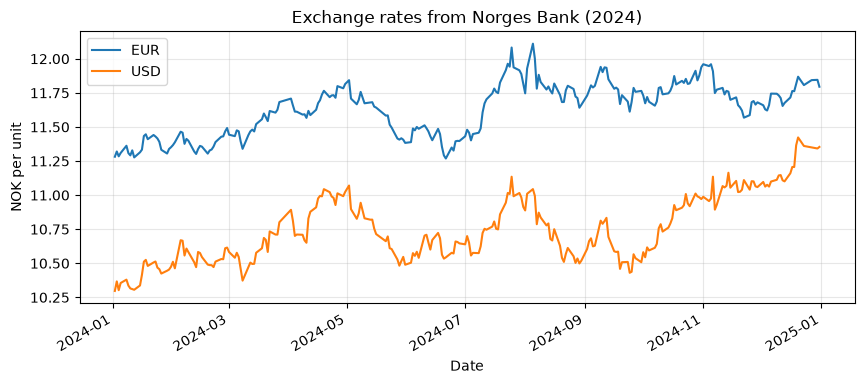

In [2]:
# Tester funksjonen for 2024, samme år som værdataene i del 3
rates = download_exchange_rates("2024-01-01", "2024-12-31")
print("Antall dager:", len(rates))   # rundt 250, fordi helger og helligdager mangler
print(rates.describe().round(2))

# Plotter begge kursene i samme figur
fig, ax = plt.subplots(figsize=(10, 4))
rates.plot(ax=ax)
ax.set_title("Exchange rates from Norges Bank (2024)")
ax.set_xlabel("Date")
ax.set_ylabel("NOK per unit")
ax.grid(alpha=0.3)
plt.show()

Funksjonen virker: den henter 251 dager for 2024, med kurser for både euro og dollar. Det er bare virkedager, fordi Norges Bank ikke publiserer kurser i helger og på helligdager. Når kursene skal brukes sammen med magasinstatistikken, som er ukentlig, må de derfor gjøres om til samme tidsoppløsning, for eksempel gjennomsnitt per uke.